##Connecting to Google drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Importing libraries and defining datasets paths

In [4]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import gc
import random

TRAIN_PATH = '/content/drive/MyDrive/training_data.npz'
TEST_PATH = '/content/drive/MyDrive/testing_data.npz'

##Data preprocessing

The channels statistics are computed to visualize the distribution of the data. A z-score normalization was applied to reduce data scale, to speed up computation and to avoid exploding gradient issues.

After standardization, the dataset is split into training and validation sets. Redundant data are deleted to reduce RAM usage. Once loaded, the test set gets normalized too.

In [5]:
train_data = np.load(TRAIN_PATH)

x_raw = train_data['x'].astype('float32')
y = train_data['y'].astype('float32')
y = np.expand_dims(y, axis=-1)

del train_data
gc.collect()



num_channels = x_raw.shape[-1]

print("Separated channels statistics:")
for i in range(num_channels):
    channel_data = x_raw[..., i]
    print(f"Channel {i}:")
    print(f"  - Mean: {np.mean(channel_data):.2f}")
    print(f"  - Std:   {np.std(channel_data):.2f}")
    print(f"  - Max:   {np.max(channel_data):.2f}")
    print(f"  - Min:   {np.min(channel_data):.2f}")



mean_train = np.mean(x_raw)
std_train = np.std(x_raw)

def standardize(data, mean, std):
    return (data - mean) / (std + 1e-7)

x_standardized = standardize(x_raw, mean_train, std_train)

del x_raw
gc.collect()



x_train, x_val, y_train, y_val = train_test_split(
    x_standardized, y, test_size=0.2, random_state=42
)

del x_standardized, y
gc.collect()



test_data = np.load(TEST_PATH)
x_test_raw = test_data['x'].astype('float32')
x_test = standardize(x_test_raw, mean_train, std_train)

del test_data, x_test_raw
gc.collect()


print("\nNormalized data statistics:")
print(f" - Train: {x_train.shape}, Mean: {np.mean(x_train):.4f}")
print(f" - Val:   {x_val.shape}, Mean: {np.mean(x_val):.4f}")
print(f" - Test:  {x_test.shape}, Mean: {np.mean(x_test):.4f}")
print(f" - Train: {x_train.shape}, STD: {np.std(x_train):.4f}")
print(f" - Val:   {x_val.shape}, STD: {np.std(x_val):.4f}")
print(f" - Test:  {x_test.shape}, STD: {np.std(x_test):.4f}")

Separated channels statistics:
Channel 0:
  - Mean: 3689.60
  - Std:   4114.87
  - Max:   20896.00
  - Min:   0.00
Channel 1:
  - Mean: 3620.80
  - Std:   3737.11
  - Max:   19536.00
  - Min:   0.00
Channel 2:
  - Mean: 3395.57
  - Std:   3551.50
  - Max:   18416.00
  - Min:   0.00
Channel 3:
  - Mean: 4275.55
  - Std:   2931.44
  - Max:   16865.00
  - Min:   0.00

Normalized data statistics:
 - Train: (32000, 64, 64, 4), Mean: 0.0026
 - Val:   (8000, 64, 64, 4), Mean: -0.0104
 - Test:  (4096, 64, 64, 4), Mean: -0.2178
 - Train: (32000, 64, 64, 4), STD: 1.0015
 - Val:   (8000, 64, 64, 4), STD: 0.9941
 - Test:  (4096, 64, 64, 4), STD: 0.7999


Distribution of the masks is computed to evaluate an imbalance in the data. Data are neither perfectly balanced nor so unbalanced to require manipulation, at least at a first look.

/tmp/ipykernel_5191/229499557.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()



 Statistics:
 - Images: 32000
 - Empty (<= 1%): 5258
 - Normal coverage : 12459
 - Full (>= 95%): 14283


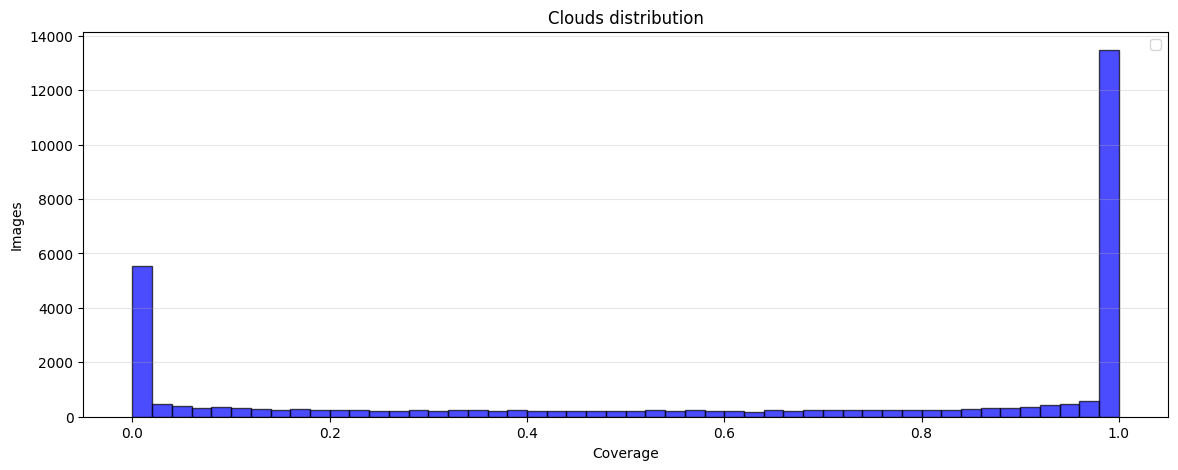

In [15]:
clouds_mean = np.mean(y_train, axis=(1, 2, 3))

plt.figure(figsize=(14, 5))

plt.hist(clouds_mean, bins=50, edgecolor='black', color='blue', alpha=0.7)
plt.xlabel('Coverage')
plt.ylabel('Images')
plt.title('Clouds distribution')
plt.legend()
plt.grid(axis='y', alpha=0.3)


print(f"\n Statistics:")
print(f" - Images: {len(clouds_mean)}")
print(f" - Empty (<= 1%): {np.sum(clouds_mean <= 0.01)}")
print(f" - Normal coverage : {len(clouds_mean) - np.sum(clouds_mean <= 0.01) - np.sum(clouds_mean >= 0.95)}")
print(f" - Full (>= 95%): {np.sum(clouds_mean >= 0.95)}")

##Definition of the model

For solving the task of binary segmentation a quite simple FCN has been defined.

Instead of using the standard "Conv2D" it was opted for the "SeparableConv2D" as it requires far less parameters, which is good as one of the evaluation factors of the model is it's size.

For the image downscaling section both striding and MaxPooling2D have been attempted and gave similar results. Since MaxPooling2D requires to save no parameters to work, it has been chosen.

Since we are treating segmentation with only 2 classes it's possible to use the sigmoid function instead of the softmax.

In addition to pixel wise accuracy, the BinaryIoU is monitored with a decision threshold of 0,5 .

The architecture was reduced to the bare minimum to reduce the size.


In [6]:
model = tf.keras.Sequential([

    tf.keras.Input(shape=(64, 64, 4)),

    layers.SeparableConv2D(32, (3, 3), padding='same'),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(64, (3, 3), padding='same'),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.SeparableConv2D(128, (3, 3), padding='same'),
    layers.ReLU(),

    layers.Conv2DTranspose(64, (3, 3), strides=(2, 2), padding='same'),
    layers.ReLU(),

    layers.Conv2DTranspose(32, (3, 3), strides=(2, 2), padding='same'),
    layers.ReLU(),

    layers.Conv2D(1, (1, 1)),
    layers.Activation('sigmoid')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.BinaryIoU(threshold=0.5)]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d                │ (None, 64, 64, 32)     │           196 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 1)      │            33 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,781 (405.39 KB)

 Trainable params: 103,781 (405.39 KB)

 Non-trainable params: 0 (0.00 B)

Code used to visualize the network architecture

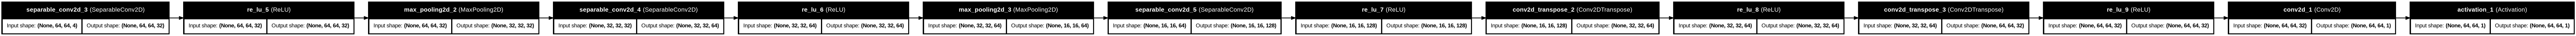

In [17]:
tf.keras.utils.plot_model(
    model,
    to_file='model_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    rankdir='LR', #TB verticale
    expand_nested=True,
    dpi=96
)

##Model fitting

The parameters for the fitting phase have been tuned after many iterations with a batch size of 32, that seems to work the best.

The number of epochs has been set to 50, yet the fitting is expected to converge earlier. To avoid overfitting, a callback has been set up to stop the process once the validation loss stops decreasing.


In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

history = model.fit(
    x_train, y_train,
    epochs=50,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

##Converting the model into tflite format and saving it
No optimization has been used.

Restricting the model conversion to built-in operations ensures maximum compatibility.

In [7]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]

try:
    tflite_model = converter.convert()
    with open('model.tflite', 'wb') as f:
        f.write(tflite_model)
    print("Conversion completed")
except Exception as e:
    print(f"Conversion error : {e}")

Saved artifact at '/tmp/tmppki7tcee'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 4), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 64, 64, 1), dtype=tf.float32, name=None)
Captures:
  132418711754640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711752528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711755984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711755792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711755408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711755600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711756176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711754832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711756944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132418711755216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13241871

##Computing predictions.npy
Set up of the TFLite interpreter

In [8]:
interpreter = tf.lite.Interpreter(model_path='/content/drive/MyDrive/model.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Since the TFLite interpreter is able to process only one sample at a time, inference is performed iteratively through a for cycle.

Once all samples have been processed, the individual outputs are stacked into a single array to reconstruct the full set of predictions.

Since the model performs binary classification, the continuous output values are converted into binary predictions by applying a threshold at 0.5. The resulting binary predictions are then reshaped to produce the prediction vector.

Finally the predictions are saved in the .npy format.

In [20]:
tflite_preds_list = []

for i in range(x_test.shape[0]):

    input_data = np.expand_dims(x_test[i], axis=0).astype(np.float32)

    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()

    output_data = interpreter.get_tensor(output_details[0]['index'])
    tflite_preds_list.append(output_data)

tflite_preds = np.vstack(tflite_preds_list)

tflite_preds_binary = (tflite_preds > 0.5).astype('uint8')

predictions_final = np.squeeze(tflite_preds_binary)

np.save('predictions.npy', predictions_final)

print(f"File predictions.npy generated")

KeyboardInterrupt: 

##Predicting masks
The following function is used to visualize the predictions made by the model. At random, it chooses 8 consecutive 64x64 patches to infere on, then both the patches and the masks are arranged to create 512x512 images displayed together for reference.




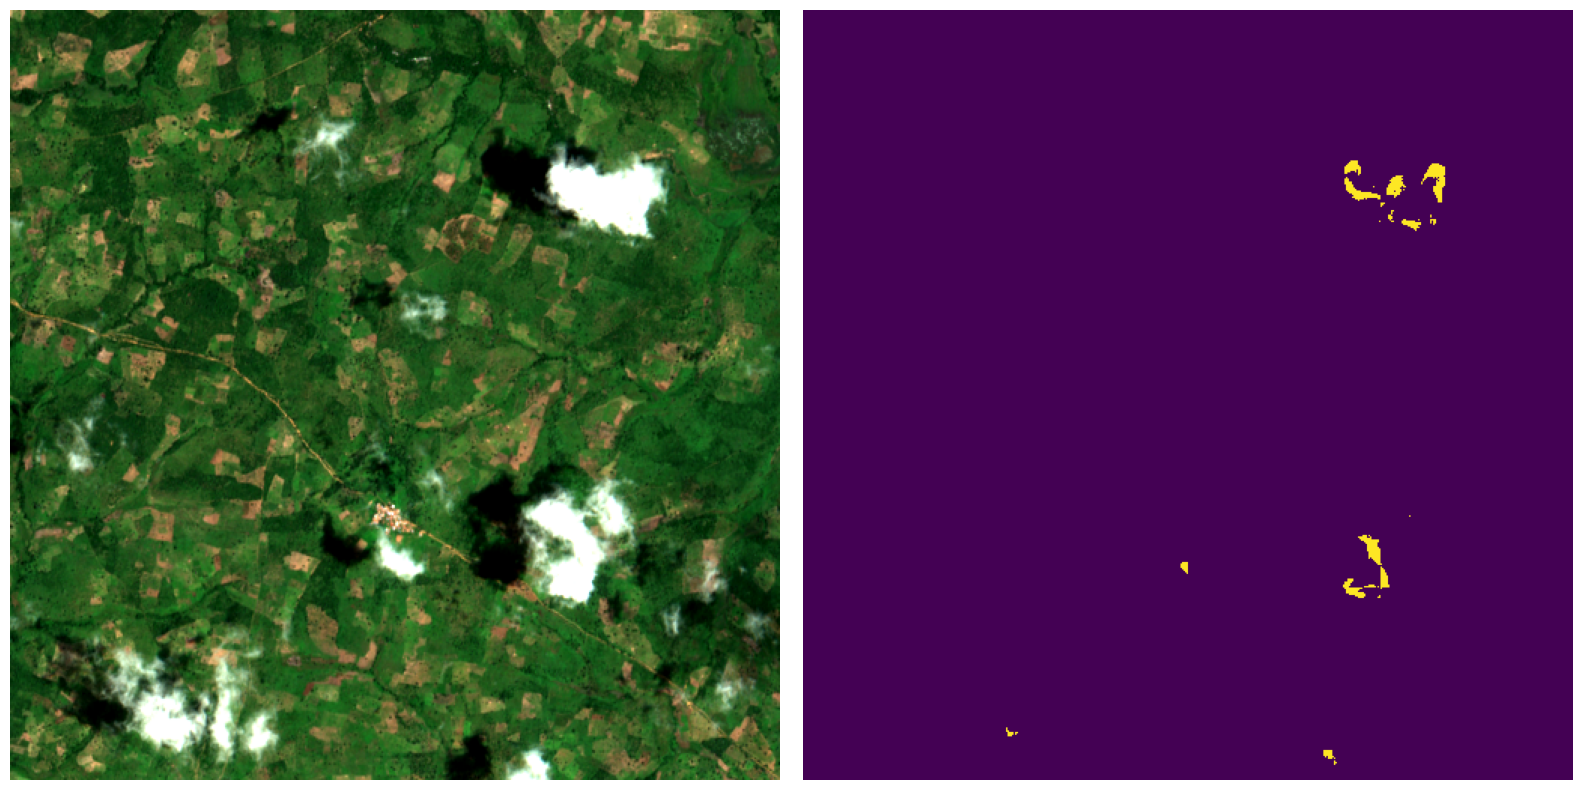

In [29]:
def create_mask(x_data, interpreter, input_details, output_details):


    num_full_images = len(x_data) // 64
    random_img_idx = random.randint(0, num_full_images - 1)
    start_idx = random_img_idx * 64

    patches_input = []
    patches_pred = []


    for i in range(64):
        img_patch = x_data[start_idx + i]


        input_tensor = np.expand_dims(img_patch, axis=0).astype(np.float32)
        interpreter.set_tensor(input_details[0]['index'], input_tensor)
        interpreter.invoke()

        pred_prob = interpreter.get_tensor(output_details[0]['index'])
        mask_patch = (pred_prob > 0.5).astype(np.uint8).squeeze()

        patches_input.append(img_patch)
        patches_pred.append(mask_patch)



    rows_img = []
    rows_mask = []

    for r in range(8):

        row_i = np.concatenate(patches_input[r*8 : (r+1)*8], axis=1)
        row_m = np.concatenate(patches_pred[r*8 : (r+1)*8], axis=1)
        rows_img.append(row_i)
        rows_mask.append(row_m)


    full_img_standardized = np.concatenate(rows_img, axis=0)
    full_mask = np.concatenate(rows_mask, axis=0)

    rgb = full_img_standardized[:, :, [2, 1, 0]].copy()
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb_vis = np.clip((rgb - p2) / (max(p98 - p2, 1e-7)), 0, 1)

    plt.figure(figsize=(16, 8))

    plt.subplot(1, 2, 1)
    plt.imshow(rgb_vis)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(full_mask, cmap='viridis')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


create_mask(x_test, interpreter, input_details, output_details)